# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 10: Synthetic Image Generation

### Objective

This notebook uses the generator trained in Notebook 09 to turn the few real images of every **training** identity into many more:

```text
2 real images  ->  generator  ->  18 synthetic images   =   20 images for that identity
```

The notebook must:

1. Load the Notebook 09 generator (one per shot count) and the identity embeddings of Notebook 08.
2. For every training identity keep its identity embedding fixed and draw different appearance codes, so the new images show the **same iris under different conditions**.
3. Store every generated image in `generated_images/`, together with a manifest.
4. Show **real versus generated** images and compare their basic statistics.

### Important boundary of this notebook

This notebook performs **generation and storage only**.

It does **not** decide which synthetic images are good: **nothing is filtered here**. Identity verification (Notebook 11) and diversity analysis (Notebook 12) come next, and Notebook 13 trains on the real images plus the synthetic images that were accepted. Only identities of the **training split** are used; validation, test, and unseen-dataset identities are never generated.

## 1. Research rationale

### 1.1 What is generated

For a shot count `K` and a target of `N` images per identity (`TARGET_TOTAL_PER_IDENTITY`, default 20, as in the project plan "2 images -> 20 images"), every training identity receives `N - K` synthetic images:

| Shot `K` | Real images | Synthetic images | Total (default `N = 20`) |
|---|---|---|---|
| 1 | 1 | 19 | 20 |
| 2 | 2 | 18 | 20 |
| 3 | 3 | 17 | 20 |
| 5 | 5 | 15 | 20 |

### 1.2 How each image is conditioned

```text
identity embedding of the person   (Notebook 08, from the K real support images, kept fixed)
+ appearance code                  (drawn at random from the generator's appearance bank)
+ starting noise                   (seeded for this one image)
        -> diffusion generator (DDIM sampling with classifier-free guidance) -> iris strip
```

- The **identity** is the same for all images of a person; the **appearance code** changes from image to image, which is where the variation comes from. The bank contains realistic appearance codes of the training images (plain and transformed views), so the appearances are plausible ones.
- The starting noise of every image is seeded by `(GENERATION_SEED, identity, index)`. Therefore every image is reproducible up to floating-point rounding: an interrupted run can be resumed, and an image generated in a different batch differs from the original only by a few gray levels in a few pixels (invisible, and smaller than the 8-bit quantisation of most pixels). (With `ETA_OVERRIDE > 0` extra noise is added during sampling, which is then no longer exactly reproducible.)
- Images are stored as 8-bit PNG files of the same size (64 x 512) as the real few-shot images, so later notebooks can load real and synthetic images in the same way.

### 1.3 Why nothing is filtered here

A generated image can look fine and still not be the requested person. Deciding that needs a recognizer and a threshold, which is Notebook 11's job. This notebook therefore keeps **every** image and records simple per-image statistics (mean, spread, sharpness, content hash) so that blank or duplicated images can be spotted.

### 1.4 Protocol and leakage rules

- Synthetic images are generated **only** for the identities the generator was trained on (the `train / support` identities). The notebook checks that each of them is a training identity, that its identity embedding comes from the training split, and that none of its people appears in the validation, test, or unseen-dataset splits.
- The synthetic images keep `split = train`. They may be used for training only; validation and test stay real.
- Nothing is written into the real few-shot dataset.

### 1.5 Things to keep in mind

- **The images are only as good as the Notebook 09 generator.** Look at the figures (section 14) before generating all shots.
- **Storage:** about 25,000 images per shot for the full CASIA training split, roughly 20-40 KB each.
- **Time:** the log prints speed and an ETA. `SAMPLE_STEPS_OVERRIDE = 25` roughly halves the time at some cost in quality; `MAX_IDENTITIES` limits the number of identities for a trial.
- **Run `QUICK_TEST = True` first.**
- **Windows:** no NumPy matrix multiplication is used; PyTorch is imported first.

In [1]:
# ============================================================
# 2. Imports
# ============================================================

import os

# Windows: PyTorch and NumPy can each load their own copy of the OpenMP runtime, and the
# second copy aborts the process at the first NumPy matrix multiplication (the notebook
# kernel "dies"). This must be set BEFORE NumPy / PyTorch are imported.
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import hashlib
import json
import math
import random
import time
import warnings
import zlib
from pathlib import Path

# PyTorch is imported first on purpose (avoids DLL-loading conflicts on Windows).
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
except ImportError as error:
    raise ImportError(
        "Notebook 10 needs PyTorch. Install it in the 'Synthetic Iris' environment, "
        "e.g. `pip install torch torchvision`."
    ) from error

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

PyTorch version: 2.14.1+cu130
OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths (inputs)
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

NOTEBOOK06_RESULTS_DIR = PROJECT_ROOT / "results" / "fewshot_dataset"
MANIFEST_LONG_PATH = NOTEBOOK06_RESULTS_DIR / "manifests" / "fewshot_manifest_long.csv"

print("Project root:", PROJECT_ROOT)
print("Notebook 06 few-shot dataset:", NOTEBOOK06_RESULTS_DIR)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation
Notebook 06 few-shot dataset: E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset


## 4. Configuration

Every setting that can change a result is here and is folded into a **configuration fingerprint**: a finished run is skipped on re-run only if its stored fingerprint matches.

- `QUICK_TEST = True` generates a handful of images for a few identities to check the whole pipeline. It reads **Notebook 09's quick-test generators** and writes to `generated_images_quicktest/`.
- `GENERATOR_SEED` and the `LATENT_*` settings must match the Notebook 09 run (its generators are named `diffusion__<K>shot__seed<GENERATOR_SEED>`).
- `TARGET_TOTAL_PER_IDENTITY` is the number of images (real + synthetic) every identity should end up with.
- `SAMPLE_STEPS_OVERRIDE`, `GUIDANCE_OVERRIDE`, `ETA_OVERRIDE`: `None` means "use the settings stored with the generator".
- Images already on disk are reused only if the settings that produced them are unchanged; otherwise they are deleted and regenerated.

In [3]:
# ============================================================
# 4. Configuration
# ============================================================

QUICK_TEST = False          # True = tiny smoke test, written to a separate folder

# ---- what to run ----
SHOTS_TO_RUN = [1, 2, 3, 5]
GENERATOR_SEED = 42         # which Notebook 09 generator to use: diffusion__<K>shot__seed<GENERATOR_SEED>
GENERATION_SEED = 1234      # seed of the random choices made here (appearance codes, starting noise)
TRAIN_DATASETS = ["CASIA-Iris-Thousand"]

# ---- upstream settings: must match the Notebook 08 / 09 runs ----
LATENT_ENCODER = "cnn"
LATENT_MODE = "vae"
LATENT_SEED = 42
UPSTREAM_FROM_QUICKTEST = QUICK_TEST    # QUICK_TEST reads the quick-test outputs of Notebooks 08 and 09

INPUT_HW = (64, 512)        # normalized iris strips

# ---- how many images ----
TARGET_TOTAL_PER_IDENTITY = 20   # real + synthetic images per identity ("2 images -> 20 images")
MAX_IDENTITIES = None            # e.g. 50 for a trial; None = every training identity

# ---- sampling (None = the settings stored with the generator) ----
SAMPLE_STEPS_OVERRIDE = None     # e.g. 25 to generate about twice as fast
GUIDANCE_OVERRIDE = None
ETA_OVERRIDE = None
SAMPLE_BATCH_SIZE = 32
MIXED_PRECISION = True           # used only on CUDA

# ---- figures ----
FIGURE_IDENTITIES = 4
FIGURE_GENERATED = 4

# ---- bookkeeping ----
RESUME = True                    # reuse images already on disk (only if produced with the same settings)
PRUNE_UNEXPECTED_FILES = True    # delete generated PNGs of this run that are not part of the current plan

if QUICK_TEST:
    SHOTS_TO_RUN = [1, 3]
    TARGET_TOTAL_PER_IDENTITY = 8
    MAX_IDENTITIES = 6
    SAMPLE_STEPS_OVERRIDE = 10
    SAMPLE_BATCH_SIZE = 16
    print("QUICK_TEST is ON: a few identities, separate output folders, reads Notebook 09's quick-test outputs.")

# ---- sanity checks on the configuration itself ----
assert tuple(INPUT_HW) == (64, 512), "This notebook assumes 64 x 512 iris strips"
assert TARGET_TOTAL_PER_IDENTITY >= 2, "TARGET_TOTAL_PER_IDENTITY must be at least 2"
assert SAMPLE_BATCH_SIZE >= 1
assert MAX_IDENTITIES is None or MAX_IDENTITIES >= 1
assert len(SHOTS_TO_RUN) >= 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = bool(MIXED_PRECISION and DEVICE.type == "cuda")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True

print("Shots:", SHOTS_TO_RUN, "| target images per identity:", TARGET_TOTAL_PER_IDENTITY,
      "| device:", DEVICE, "| mixed precision:", USE_AMP)
if DEVICE.type != "cuda":
    print("WARNING: no CUDA GPU found. Generating thousands of images on CPU is very slow; use QUICK_TEST = True.")

Shots: [1, 2, 3, 5] | target images per identity: 20 | device: cuda | mixed precision: True


In [4]:
# ============================================================
# 4b. Output and upstream locations (depend on QUICK_TEST)
# ============================================================

suffix = "_quicktest" if QUICK_TEST else ""
upstream_suffix = "_quicktest" if UPSTREAM_FROM_QUICKTEST else ""

GENERATED_DIR = PROJECT_ROOT / f"generated_images{suffix}"
RESULTS_DIR = PROJECT_ROOT / "results" / f"synthetic_generation{suffix}"
RUNS_DIR = RESULTS_DIR / "runs"
MANIFEST_DIR = RESULTS_DIR / "manifests"

GENERATOR_DIR = PROJECT_ROOT / "checkpoints" / f"diffusion_generator{upstream_suffix}"
NOTEBOOK08_RESULTS_DIR = PROJECT_ROOT / "results" / f"identity_latent_space{upstream_suffix}"

for directory in [GENERATED_DIR, RESULTS_DIR, RUNS_DIR, MANIFEST_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Generated images:", GENERATED_DIR)
print("Notebook 10 results:", RESULTS_DIR)
print("Reading generators from:", GENERATOR_DIR)
print("Reading identity embeddings from:", NOTEBOOK08_RESULTS_DIR)

Generated images: E:\Research\LargeScale_Synthetic_Iris_Generation\generated_images
Notebook 10 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_generation
Reading generators from: E:\Research\LargeScale_Synthetic_Iris_Generation\checkpoints\diffusion_generator
Reading identity embeddings from: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_latent_space


## 5. Utility functions

Images are written atomically (a temporary file that is then renamed), so an interruption can never leave a half-written PNG that looks valid. The path helpers copy the naming rules of Notebooks 05 and 06.

In [5]:
# ============================================================
# 5. Utility functions
# ============================================================

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def make_generator(seed):
    generator = torch.Generator(device=DEVICE)
    generator.manual_seed(int(seed))
    return generator


def file_digest(path):
    with open(path, "rb") as f:
        return hashlib.blake2b(f.read(), digest_size=16).hexdigest()


def file_signature(path):
    '''Size and modification time: changes whenever the file is rewritten.'''
    stat = Path(path).stat()
    return [int(stat.st_size), int(stat.st_mtime)]


def dataset_safe_name(dataset):
    return str(dataset).replace("/", "_").replace(chr(92), "_").replace(" ", "_")


def identity_safe_name(identity):
    if pd.isna(identity):
        return "unknown_identity"
    return str(identity).replace("/", "_").replace(chr(92), "_")


def eye_safe_name(eye):
    if pd.isna(eye):
        return "UNKNOWN"
    return str(eye).replace("/", "_")


def write_png_atomic(path, array_uint8):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.stem + ".tmp.png")

    if not cv2.imwrite(str(temporary), array_uint8):
        raise IOError(f"Could not write {temporary}")

    os.replace(temporary, path)


IMAGE_CACHE = {}


def read_gray_uint8(path):
    '''Read one real iris texture as a cached uint8 array of shape INPUT_HW.'''
    key = str(path)

    if key not in IMAGE_CACHE:
        image = cv2.imread(key, cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise ValueError(f"Unable to read image: {key}")

        if image.shape != tuple(INPUT_HW):
            image = cv2.resize(image, (INPUT_HW[1], INPUT_HW[0]), interpolation=cv2.INTER_AREA)

        IMAGE_CACHE[key] = image

    return IMAGE_CACHE[key]


def resolve_image_path(row):
    '''Use the Notebook 06 folder tree if present, else the Notebook 05 source file.'''
    in_tree = NOTEBOOK06_RESULTS_DIR / row.relative_path
    if in_tree.exists():
        return in_tree

    source = Path(row.source_path)
    if source.exists():
        return source

    raise FileNotFoundError(f"Image not found in the few-shot tree or at its source: {row.relative_path}")


def load_image_tensor(df):
    '''Stack the real images of a manifest slice into a uint8 tensor [N, H, W].'''
    arrays = [read_gray_uint8(resolve_image_path(row)) for row in df.itertuples(index=False)]
    return torch.from_numpy(np.stack(arrays))


def make_run_id(shot):
    return f"diffusion__{shot}shot__seed{GENERATOR_SEED}"


def generator_path(shot):
    return GENERATOR_DIR / f"{make_run_id(shot)}.pt"


def latent_run_id(shot):
    return f"{LATENT_ENCODER}_{LATENT_MODE}__{shot}shot__seed{LATENT_SEED}"


def embedding_path(shot):
    return NOTEBOOK08_RESULTS_DIR / "identity_embeddings" / f"{latent_run_id(shot)}.npz"

## 6. Load the few-shot dataset and check the upstream outputs

`fewshot_manifest_long.csv` (Notebook 06) tells which identities and images belong to the training split. For every shot you run, the Notebook 09 generator and the Notebook 08 identity embeddings must exist; the notebook checks this **before** generating anything.

A shot is skipped if `TARGET_TOTAL_PER_IDENTITY` is not larger than the shot count (there would be nothing to generate).

In [6]:
# ============================================================
# 6. Load the few-shot dataset
# ============================================================

if not MANIFEST_LONG_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 06 manifest was not found at: {MANIFEST_LONG_PATH}\n"
        "Run 06_FewShot_Dataset_Creation.ipynb first."
    )

long_manifest = pd.read_csv(MANIFEST_LONG_PATH, dtype={"identity": str, "eye": str})

required_columns = {
    "shot", "image_id", "dataset", "identity", "eye", "class_id", "subject_key",
    "split", "role", "relative_path", "source_path",
}

missing = required_columns.difference(long_manifest.columns)
if missing:
    raise ValueError(f"Notebook 06 manifest is missing required columns: {sorted(missing)}")

available_datasets = sorted(long_manifest["dataset"].unique())
available_shots = sorted(long_manifest["shot"].unique())

for dataset_name in TRAIN_DATASETS:
    assert dataset_name in available_datasets, (
        f"TRAIN_DATASETS contains '{dataset_name}', which is not in the manifest {available_datasets}"
    )

shots_to_run = [k for k in SHOTS_TO_RUN if k in available_shots]
for k in SHOTS_TO_RUN:
    if k not in available_shots:
        print(f"WARNING: {k}-shot was requested but does not exist in the manifest; skipping it.")

for k in [k for k in shots_to_run if TARGET_TOTAL_PER_IDENTITY <= k]:
    print(f"WARNING: TARGET_TOTAL_PER_IDENTITY = {TARGET_TOTAL_PER_IDENTITY} is not larger than {k}; "
          f"nothing to generate for {k}-shot, skipping it.")
shots_to_run = [k for k in shots_to_run if TARGET_TOTAL_PER_IDENTITY > k]

if not shots_to_run:
    raise RuntimeError("There is no shot count left to generate for.")

missing_upstream = [str(p) for shot in shots_to_run for p in (generator_path(shot), embedding_path(shot)) if not p.exists()]
if missing_upstream:
    raise FileNotFoundError(
        "Upstream outputs are missing:\n  " + "\n  ".join(missing_upstream)
        + "\nRun 08_Identity_Latent_Space.ipynb and 09_Diffusion_Model_Training.ipynb first "
          "(same shots, GENERATOR_SEED, LATENT_* settings; QUICK_TEST here reads their quick-test outputs)."
    )

print("Datasets in manifest:", available_datasets)
print("Training dataset(s):", TRAIN_DATASETS)
print("Shots that will be run:", shots_to_run)

overview = (
    long_manifest[
        (long_manifest["split"] == "train")
        & (long_manifest["role"] == "support")
        & (long_manifest["dataset"].isin(TRAIN_DATASETS))
        & (long_manifest["shot"].isin(shots_to_run))
    ]
    .groupby("shot")
    .agg(train_identities=("class_id", "nunique"), real_images=("image_id", "count"))
    .reset_index()
)
overview["synthetic_per_identity"] = TARGET_TOTAL_PER_IDENTITY - overview["shot"]
overview["synthetic_images_to_generate"] = overview["train_identities"] * overview["synthetic_per_identity"]
print("\nUpper bound from the manifest (the generator's own identity list decides the real numbers):")
display(overview)

# Fingerprint of everything that can change a result.
HYPERPARAMETERS = {
    "train_datasets": TRAIN_DATASETS, "generator_seed": GENERATOR_SEED, "generation_seed": GENERATION_SEED,
    "latent": [LATENT_ENCODER, LATENT_MODE, LATENT_SEED, UPSTREAM_FROM_QUICKTEST],
    "counts": [TARGET_TOTAL_PER_IDENTITY, MAX_IDENTITIES],
    "sampling": [SAMPLE_STEPS_OVERRIDE, GUIDANCE_OVERRIDE, ETA_OVERRIDE],
    "upstream": {str(shot): [file_signature(generator_path(shot)), file_signature(embedding_path(shot))]
                 for shot in shots_to_run},
    "manifest_digest": file_digest(MANIFEST_LONG_PATH),
}

CONFIG_HASH = hashlib.blake2b(
    json.dumps(HYPERPARAMETERS, sort_keys=True, default=str).encode("utf-8"), digest_size=6
).hexdigest()

print("Configuration fingerprint:", CONFIG_HASH)

Datasets in manifest: ['CASIA-Iris-Thousand', 'IITD']
Training dataset(s): ['CASIA-Iris-Thousand']
Shots that will be run: [1, 2, 3, 5]

Upper bound from the manifest (the generator's own identity list decides the real numbers):


,shot,train_identities,real_images,synthetic_per_identity,synthetic_images_to_generate
0,1,1390,1390,19,26410
1,2,1384,2768,18,24912
2,3,1369,4107,17,23273
3,5,1294,6470,15,19410


Configuration fingerprint: 653f6470d9cb


## 7. The Notebook 09 generator

The classes below are **copied from Notebook 09** so that its checkpoint can be loaded here: the U-Net, the noise schedule, DDIM sampling with classifier-free guidance, and `load_generator`. Two small changes: `sample_images` takes its sampling settings as arguments, and it accepts a ready-made **starting noise** (`x_init`), which is what makes every image reproducible and resumable.

The Notebook 08 latent model is **not** needed here: the identity embeddings are read from Notebook 08's saved arrays and the appearance codes come from the generator's own bank.

In [7]:
# ============================================================
# 7. U-Net, diffusion process, sampling (copied from Notebook 09)
# ============================================================

def timestep_embedding(t, dim):
    half = dim // 2
    frequencies = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device, dtype=torch.float32) / half)
    arguments = t.float().unsqueeze(1) * frequencies.unsqueeze(0)
    return torch.cat([torch.sin(arguments), torch.cos(arguments)], dim=1)


class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, emb_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.emb = nn.Linear(emb_dim, 2 * out_channels)          # per-channel scale and shift
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        nn.init.zeros_(self.conv2.weight)
        nn.init.zeros_(self.conv2.bias)
        self.skip = nn.Identity() if in_channels == out_channels else nn.Conv2d(in_channels, out_channels, 1)

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        scale, shift = self.emb(F.silu(emb)).unsqueeze(-1).unsqueeze(-1).chunk(2, dim=1)
        h = self.norm2(h) * (1 + scale) + shift
        h = self.conv2(F.silu(h))
        return h + self.skip(x)


class SelfAttention(nn.Module):
    def __init__(self, channels, heads):
        super().__init__()
        self.heads = heads
        self.norm = nn.GroupNorm(8, channels)
        self.qkv = nn.Conv2d(channels, 3 * channels, 1)
        self.proj = nn.Conv2d(channels, channels, 1)
        nn.init.zeros_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)

    def forward(self, x):
        b, c, h, w = x.shape
        qkv = self.qkv(self.norm(x)).reshape(b, 3, self.heads, c // self.heads, h * w)
        q, k, v = (qkv[:, i].transpose(-1, -2) for i in range(3))        # each [b, heads, tokens, d]

        if hasattr(F, "scaled_dot_product_attention"):
            out = F.scaled_dot_product_attention(q, k, v)
        else:
            attention = torch.softmax(torch.matmul(q, k.transpose(-1, -2)) / math.sqrt(q.size(-1)), dim=-1)
            out = torch.matmul(attention, v)

        return x + self.proj(out.transpose(-1, -2).reshape(b, c, h, w))


class Downsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 3, stride=2, padding=1)

    def forward(self, x):
        return self.conv(x)


class Upsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 3, padding=1)

    def forward(self, x):
        return self.conv(F.interpolate(x, scale_factor=2, mode="nearest"))


class EmbedSequential(nn.Sequential):
    '''Passes the embedding to residual blocks and only the features to every other layer.'''

    def forward(self, x, emb):
        for layer in self:
            x = layer(x, emb) if isinstance(layer, ResBlock) else layer(x)
        return x


class UNet(nn.Module):
    def __init__(self, base, mults, res_blocks, attn_levels, heads, cond_dim):
        super().__init__()
        self.base = base
        emb_dim = base * 4

        self.time_mlp = nn.Sequential(nn.Linear(base, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))
        self.cond_mlp = nn.Sequential(nn.Linear(cond_dim, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))
        self.null_cond = nn.Parameter(torch.zeros(cond_dim))      # learned "no condition" vector

        self.input_blocks = nn.ModuleList([EmbedSequential(nn.Conv2d(4, base, 3, padding=1))])
        channels = base
        skip_channels = [base]

        for level, mult in enumerate(mults):
            for _ in range(res_blocks):
                layers = [ResBlock(channels, base * mult, emb_dim)]
                channels = base * mult
                if level in attn_levels:
                    layers.append(SelfAttention(channels, heads))
                self.input_blocks.append(EmbedSequential(*layers))
                skip_channels.append(channels)
            if level != len(mults) - 1:
                self.input_blocks.append(EmbedSequential(Downsample(channels)))
                skip_channels.append(channels)

        self.middle = EmbedSequential(ResBlock(channels, channels, emb_dim), SelfAttention(channels, heads),
                                      ResBlock(channels, channels, emb_dim))

        self.output_blocks = nn.ModuleList()
        for level, mult in reversed(list(enumerate(mults))):
            for i in range(res_blocks + 1):
                layers = [ResBlock(channels + skip_channels.pop(), base * mult, emb_dim)]
                channels = base * mult
                if level in attn_levels:
                    layers.append(SelfAttention(channels, heads))
                if level != 0 and i == res_blocks:
                    layers.append(Upsample(channels))
                self.output_blocks.append(EmbedSequential(*layers))

        self.out = nn.Sequential(nn.GroupNorm(8, channels), nn.SiLU(), nn.Conv2d(channels, 4, 3, padding=1))
        nn.init.zeros_(self.out[-1].weight)
        nn.init.zeros_(self.out[-1].bias)

    def forward(self, x, t, cond):
        '''x: [B, 1, 64, 512] in [-1, 1]; t: [B] time steps; cond: [B, cond_dim] -> predicted noise [B, 1, 64, 512].'''
        emb = self.time_mlp(timestep_embedding(t, self.base)) + self.cond_mlp(cond)

        h = F.pixel_unshuffle(x, 2)
        skips = []
        for block in self.input_blocks:
            h = block(h, emb)
            skips.append(h)

        h = self.middle(h, emb)

        for block in self.output_blocks:
            h = torch.cat([h, skips.pop()], dim=1)
            h = block(h, emb)

        return F.pixel_shuffle(self.out(h), 2)


class Diffusion:
    '''Noise schedule and forward process.'''

    def __init__(self, steps, schedule):
        self.steps = steps

        if schedule == "cosine":
            grid = np.arange(steps + 1, dtype=np.float64) / steps
            f = np.cos((grid + 0.008) / 1.008 * np.pi / 2) ** 2
            alphas_cumprod = f / f[0]
            betas = np.clip(1.0 - alphas_cumprod[1:] / alphas_cumprod[:-1], 0.0, 0.999)
        else:
            betas = np.linspace(1e-4, 0.02, steps, dtype=np.float64)

        self.alphas_cumprod = torch.tensor(np.cumprod(1.0 - betas), dtype=torch.float32, device=DEVICE)

    def q_sample(self, x0, t, noise):
        a = self.alphas_cumprod[t].view(-1, 1, 1, 1)
        return a.sqrt() * x0 + (1.0 - a).sqrt() * noise

    def ddim_timesteps(self, n):
        timesteps = np.linspace(self.steps - 1, 0, n).round().astype(int).tolist()
        return list(dict.fromkeys(timesteps))


@torch.no_grad()
def sample_images(model, diffusion, cond, steps, guidance, eta, gen=None, x_init=None):
    '''DDIM sampling with classifier-free guidance.

    cond: [B, cond_dim] condition (see make_condition). x_init: optional starting noise [B, 1, 64, 512].
    Returns images in [0, 1], shape [B, 1, 64, 512].'''
    model.eval()
    batch = cond.shape[0]
    x = x_init.clone() if x_init is not None else torch.randn(batch, 1, *INPUT_HW, device=DEVICE, generator=gen)
    null = model.null_cond.unsqueeze(0).expand(batch, -1)
    timesteps = diffusion.ddim_timesteps(steps)

    for i, t in enumerate(timesteps):
        t_batch = torch.full((batch,), t, device=DEVICE, dtype=torch.long)

        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            if guidance == 1.0:
                eps = model(x, t_batch, cond)
            else:
                both = model(torch.cat([x, x]), torch.cat([t_batch, t_batch]), torch.cat([cond, null]))
                eps_cond, eps_null = both.chunk(2)
                eps = eps_null + guidance * (eps_cond - eps_null)

        eps = eps.float()
        a_t = diffusion.alphas_cumprod[t]
        a_prev = diffusion.alphas_cumprod[timesteps[i + 1]] if i + 1 < len(timesteps) else torch.ones((), device=DEVICE)

        x0 = ((x - (1.0 - a_t).sqrt() * eps) / a_t.sqrt()).clamp(-1.0, 1.0)
        eps = (x - a_t.sqrt() * x0) / (1.0 - a_t).sqrt()
        sigma = eta * ((1.0 - a_prev) / (1.0 - a_t)).sqrt() * (1.0 - a_t / a_prev).sqrt()
        direction = (1.0 - a_prev - sigma ** 2).clamp(min=0.0).sqrt() * eps
        noise = torch.randn(x.shape, device=DEVICE, generator=gen) if eta > 0 else 0.0
        x = a_prev.sqrt() * x0 + direction + sigma * noise

    return (x.clamp(-1.0, 1.0) + 1.0) / 2.0


def make_condition(identity_unit, app_norm):
    '''identity_unit: [B, id_dim] unit-length identity embeddings; app_norm: [B, app_dim] standardised appearance codes.'''
    return torch.cat([identity_unit * math.sqrt(identity_unit.shape[1]), app_norm], dim=1)


def load_generator(path):
    '''Rebuild a trained generator (EMA weights) from a Notebook 09 checkpoint.'''
    try:
        checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        checkpoint = torch.load(path, map_location="cpu")

    model = UNet(**checkpoint["unet_args"]).to(DEVICE)
    model.load_state_dict(checkpoint["ema_state"])
    return model.eval(), checkpoint

In [8]:
# ============================================================
# 7b. Self-test of the sampler (small network)
# ============================================================

torch.manual_seed(0)
test_net = UNet(base=16, mults=[1, 2, 4, 4], res_blocks=1, attn_levels=[3], heads=4, cond_dim=10).to(DEVICE)
test_diffusion = Diffusion(1000, "cosine")
test_cond = torch.randn(3, 10, device=DEVICE)

with torch.no_grad():
    for parameter in test_net.parameters():
        parameter.add_(0.02 * torch.randn_like(parameter))

noise_a = torch.randn(3, 1, *INPUT_HW, device=DEVICE)
noise_b = torch.randn(3, 1, *INPUT_HW, device=DEVICE)

first = sample_images(test_net, test_diffusion, test_cond, steps=3, guidance=2.0, eta=0.0, x_init=noise_a)
second = sample_images(test_net, test_diffusion, test_cond, steps=3, guidance=2.0, eta=0.0, x_init=noise_a)
other = sample_images(test_net, test_diffusion, test_cond, steps=3, guidance=2.0, eta=0.0, x_init=noise_b)

assert first.shape == noise_a.shape and torch.isfinite(first).all() and first.min() >= 0 and first.max() <= 1, "bad samples"
assert torch.allclose(first, second), "the same starting noise must give the same image"
assert not torch.allclose(first, other), "a different starting noise must give a different image"

# An image must not depend on which other images are in its batch. GPU kernels add numbers in a slightly
# different order for a different batch size, and the first sampling step divides by a tiny number
# (about 5e-5), so tiny rounding differences are magnified in a few pixels. The images are therefore
# compared on average, and the batch effect must be far smaller than the effect of a different noise.
alone = sample_images(test_net, test_diffusion, test_cond[:1], steps=3, guidance=2.0, eta=0.0, x_init=noise_a[:1])
batch_effect = float((alone - first[:1]).abs().mean())
noise_effect = float((first - other).abs().mean())
assert batch_effect < 1e-3 and batch_effect < 0.01 * noise_effect, (
    f"an image changed when generated in a different batch (mean change {batch_effect:.2e}, "
    f"a different starting noise changes it by {noise_effect:.2e})")

del test_net
print(f"Sampler self-tests passed (batch effect {batch_effect:.1e} vs. different-noise effect {noise_effect:.1e}).")

Sampler self-tests passed (batch effect 6.1e-05 vs. different-noise effect 5.0e-01).


## 8. Inputs for one shot, with the leakage guards

`load_generation_inputs(shot)` loads the generator, the identity embeddings, and the appearance bank, and then **refuses to continue** unless:

- the generator was trained on the Notebook 08 latent model this notebook is configured for;
- every identity to generate for is a **training** identity (`train / support` of `TRAIN_DATASETS`);
- its identity embedding is marked `train` in Notebook 08's file, and exists;
- none of its people appears in the validation, test, or unseen-dataset splits.

If `MAX_IDENTITIES` is set, a fixed, shot-independent subset of the identities is used.

In [9]:
# ============================================================
# 8. Generation inputs and leakage guards
# ============================================================

def load_generation_inputs(shot):
    model, checkpoint = load_generator(generator_path(shot))

    assert checkpoint["latent_run_id"] == latent_run_id(shot), (
        f"The generator was trained on latent model '{checkpoint['latent_run_id']}' but this notebook is configured "
        f"for '{latent_run_id(shot)}'. Check LATENT_ENCODER / LATENT_MODE / LATENT_SEED."
    )

    embeddings = np.load(embedding_path(shot), allow_pickle=False)
    class_list = embeddings["class_id"].tolist()
    table = dict(zip(class_list, embeddings["embedding"]))
    embedding_split = dict(zip(class_list, embeddings["split"].tolist()))

    classes = sorted(checkpoint["train_classes"])

    shot_rows = long_manifest[long_manifest["shot"] == shot]
    train_support = shot_rows[
        (shot_rows["split"] == "train") & (shot_rows["role"] == "support") & (shot_rows["dataset"].isin(TRAIN_DATASETS))
    ]
    allowed = set(train_support["class_id"])

    not_training = [c for c in classes if c not in allowed]
    assert not not_training, f"{len(not_training)} identities are not training identities, e.g. {not_training[:3]}"

    wrong_embedding_split = [c for c in classes if embedding_split.get(c) != "train"]
    assert not wrong_embedding_split, (
        f"{len(wrong_embedding_split)} identity embeddings are missing or not from the training split")

    if MAX_IDENTITIES is not None:
        classes = sorted(sorted(classes, key=lambda c: (zlib.crc32(c.encode("utf-8")), c))[:MAX_IDENTITIES])

    class_meta = shot_rows.drop_duplicates("class_id").set_index("class_id")[["dataset", "identity", "eye", "subject_key"]]
    meta = {c: tuple(class_meta.loc[c]) for c in classes}

    held_out_subjects = set(shot_rows.loc[~shot_rows["class_id"].isin(allowed), "subject_key"])
    generated_subjects = {m[3] for m in meta.values()}
    assert not (generated_subjects & held_out_subjects), "a person from the validation/test/unseen data is among the identities"

    steps = int(SAMPLE_STEPS_OVERRIDE if SAMPLE_STEPS_OVERRIDE is not None else checkpoint["sample_steps"])
    guidance = float(GUIDANCE_OVERRIDE if GUIDANCE_OVERRIDE is not None else checkpoint["guidance_scale"])
    eta = float(ETA_OVERRIDE if ETA_OVERRIDE is not None else checkpoint["ddim_eta"])

    return {
        "model": model, "checkpoint": checkpoint, "classes": classes, "meta": meta, "table": table,
        "diffusion": Diffusion(checkpoint["diffusion_steps"], checkpoint["noise_schedule"]),
        "app_bank": checkpoint["app_bank"], "steps": steps, "guidance": guidance, "eta": eta,
    }


def synthetic_relative_path(run_id, class_id, index, meta):
    dataset, identity, eye, _ = meta[class_id]
    return (Path(run_id) / dataset_safe_name(dataset) / f"{identity_safe_name(identity)}_{eye_safe_name(eye)}"
            / f"syn_{index:03d}.png")


def bank_indices_for(class_id, count, bank_size):
    '''The appearance codes of one identity: random, without repeats when the bank is large enough.'''
    rng = np.random.default_rng([GENERATION_SEED, zlib.crc32(class_id.encode("utf-8"))])
    return rng.choice(bank_size, count, replace=bank_size < count)


def starting_noise(class_id, index):
    seed = zlib.crc32(f"{GENERATION_SEED}|{class_id}|{index}".encode("utf-8"))
    return torch.randn(1, 1, *INPUT_HW, generator=torch.Generator().manual_seed(seed))

## 9. Generating the images of one shot

`generate_for_run(shot)`:

1. Loads the inputs (and runs the leakage guards).
2. **Deletes stale images** if the settings that produced the images already in the folder differ from the current ones (stored in `generation_signature.json`), and deletes files that are not part of the current plan.
3. Generates **only the missing images**, in batches. Every image is written atomically.
4. Reads **every** expected image back, checks it, and records its statistics. Unreadable or wrong-size files are deleted and regenerated once.
5. Saves the manifest of this shot to `manifests/<run_id>.csv`.

The manifest keeps, per image: identity, split (always `train`), the index and appearance-bank entry used, the sampling settings, the relative path inside `generated_images/`, mean / spread / sharpness, and a content hash.

In [10]:
# ============================================================
# 9. Generate the images of one shot
# ============================================================

def generate_for_run(shot):
    started = time.time()
    inputs = load_generation_inputs(shot)
    model, diffusion = inputs["model"], inputs["diffusion"]
    classes, meta, table, app_bank = inputs["classes"], inputs["meta"], inputs["table"], inputs["app_bank"]
    steps, guidance, eta = inputs["steps"], inputs["guidance"], inputs["eta"]

    run_id = make_run_id(shot)
    n_synthetic = TARGET_TOTAL_PER_IDENTITY - shot
    run_dir = GENERATED_DIR / run_id
    run_dir.mkdir(parents=True, exist_ok=True)

    print(f"  {len(classes)} identities x {n_synthetic} synthetic images = {len(classes) * n_synthetic} images "
          f"(steps {steps}, guidance {guidance}, eta {eta})")

    # ---- stale images: delete them if they were made with different settings ----
    signature = {"generator": file_signature(generator_path(shot)), "embeddings": file_signature(embedding_path(shot)),
                 "steps": steps, "guidance": guidance, "eta": eta, "generation_seed": int(GENERATION_SEED)}
    signature_path = run_dir / "generation_signature.json"

    stale = not RESUME
    if signature_path.exists():
        with open(signature_path) as f:
            stale = stale or json.load(f) != signature
    elif any(run_dir.rglob("*.png")):
        stale = True                                  # images of unknown origin

    if stale:
        removed = 0
        for path in run_dir.rglob("*.png"):
            path.unlink()
            removed += 1
        if removed:
            print(f"  removed {removed} existing images (settings changed or RESUME is off)")

    with open(signature_path, "w") as f:
        json.dump(signature, f)

    def image_path(class_id, index):
        return GENERATED_DIR / synthetic_relative_path(run_id, class_id, index, meta)

    expected = {image_path(c, i) for c in classes for i in range(n_synthetic)}

    if PRUNE_UNEXPECTED_FILES:
        pruned = 0
        for path in run_dir.rglob("*.png"):
            if path not in expected:
                path.unlink()
                pruned += 1
        if pruned:
            print(f"  removed {pruned} files that are not part of the current plan")

    # ---- generation of the missing images ----
    bank_choice = {c: bank_indices_for(c, n_synthetic, len(app_bank)) for c in classes}
    prototypes = {c: F.normalize(torch.as_tensor(table[c], dtype=torch.float32), dim=0) for c in classes}

    def generate(items):
        if not items:
            return
        total_batches = math.ceil(len(items) / SAMPLE_BATCH_SIZE)
        report_every = max(1, total_batches // 20)
        loop_started = time.time()

        for b, start in enumerate(range(0, len(items), SAMPLE_BATCH_SIZE), start=1):
            chunk = items[start:start + SAMPLE_BATCH_SIZE]
            identity = torch.stack([prototypes[c] for c, _ in chunk]).to(DEVICE)
            app = app_bank[torch.as_tensor([int(bank_choice[c][i]) for c, i in chunk])].to(DEVICE)
            noise = torch.cat([starting_noise(c, i) for c, i in chunk]).to(DEVICE)

            images = sample_images(model, diffusion, make_condition(identity, app), steps, guidance, eta,
                                   gen=make_generator(GENERATION_SEED + start), x_init=noise)

            if not bool(torch.isfinite(images).all()):
                raise RuntimeError("The generator produced non-finite pixels; stopping before writing anything.")

            arrays = (images.clamp(0.0, 1.0) * 255.0).round().to(torch.uint8)[:, 0].cpu().numpy()
            for (class_id, index), array in zip(chunk, arrays):
                write_png_atomic(image_path(class_id, index), array)

            if b % report_every == 0 or b == total_batches:
                elapsed = time.time() - loop_started
                done = min(start + SAMPLE_BATCH_SIZE, len(items))
                print(f"    {done}/{len(items)} images | {done / elapsed:.1f} images/s | "
                      f"ETA {(len(items) - done) / (done / elapsed) / 60:.1f} min")

    to_generate = [(c, i) for c in classes for i in range(n_synthetic) if not image_path(c, i).exists()]
    n_reused = len(expected) - len(to_generate)
    print(f"  {n_reused} images already on disk, {len(to_generate)} to generate")
    generate(to_generate)

    # ---- read every image back, check it, record its statistics ----
    def collect_rows():
        rows, bad = [], []
        for c in classes:
            dataset, identity, eye, subject_key = meta[c]
            for i in range(n_synthetic):
                path = image_path(c, i)
                array = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE) if path.exists() else None

                if array is None or array.shape != tuple(INPUT_HW):
                    bad.append((c, i))
                    continue

                x = array.astype(np.float32) / 255.0
                rows.append({
                    "image_id": f"{run_id}|{c}|syn_{i:03d}", "class_id": c, "dataset": dataset, "identity": identity,
                    "eye": eye, "subject_key": subject_key, "shot": shot, "split": "train", "source": "synthetic",
                    "synth_index": i, "bank_index": int(bank_choice[c][i]),
                    "relative_path": str(synthetic_relative_path(run_id, c, i, meta).as_posix()),
                    "generator_run_id": run_id, "latent_run_id": latent_run_id(shot),
                    "sample_steps": steps, "guidance": guidance, "eta": eta, "generation_seed": int(GENERATION_SEED),
                    "pixel_mean": float(x.mean()), "pixel_std": float(x.std()),
                    "sharpness": float(np.abs(np.diff(x, axis=1)).mean()),
                    "content_hash": hashlib.blake2b(array.tobytes(), digest_size=8).hexdigest(),
                })
        return rows, bad

    rows, bad = collect_rows()

    if bad:
        print(f"  {len(bad)} images were missing or unreadable; regenerating them once")
        for class_id, index in bad:
            image_path(class_id, index).unlink(missing_ok=True)
        generate(bad)
        rows, bad = collect_rows()
        if bad:
            raise RuntimeError(f"{len(bad)} images are still missing or unreadable after regenerating them")

    manifest = pd.DataFrame(rows)
    manifest_path = MANIFEST_DIR / f"{run_id}.csv"
    manifest.to_csv(manifest_path, index=False)

    return {
        "run_id": run_id, "config_hash": CONFIG_HASH, "shot": int(shot), "generator_seed": int(GENERATOR_SEED),
        "generator": str(generator_path(shot)), "n_identities": len(classes),
        "synthetic_per_identity": int(n_synthetic), "n_images": int(len(manifest)),
        "n_generated_now": int(len(to_generate)), "n_reused": int(n_reused),
        "sample_steps": steps, "guidance": guidance, "eta": eta,
        "seconds": float(time.time() - started), "manifest": str(manifest_path),
        "leakage_checks_passed": True,
    }

## 10. Run plan and execution

One run per shot. A finished shot is skipped on re-run if its stored fingerprint matches. A shot that was **interrupted part-way** is not marked finished, so it runs again, but it reuses every image already written (see section 9), so only the missing images are generated.

In [11]:
# ============================================================
# 10a. Run plan
# ============================================================

plan = list(shots_to_run)


def run_json_path(shot):
    return RUNS_DIR / f"{make_run_id(shot)}.json"


def is_finished(shot):
    path = run_json_path(shot)
    if not (RESUME and path.exists()):
        return False
    try:
        with open(path) as f:
            record = json.load(f)
        return record.get("config_hash") == CONFIG_HASH and Path(record["manifest"]).exists()
    except (json.JSONDecodeError, OSError, KeyError):
        return False


plan_df = pd.DataFrame({"shot": plan})
plan_df["already_done"] = [is_finished(shot) for shot in plan]

print(f"Planned runs: {len(plan_df)} | already finished: {int(plan_df['already_done'].sum())} | "
      f"to generate now: {int((~plan_df['already_done']).sum())}")
display(plan_df)

Planned runs: 4 | already finished: 0 | to generate now: 4


,shot,already_done
0,1,False
1,2,False
2,3,False
3,5,False


In [12]:
# ============================================================
# 10b. Execute the plan
# ============================================================

for position, shot in enumerate(plan, start=1):
    run_id = make_run_id(shot)

    if is_finished(shot):
        print(f"[{position}/{len(plan)}] {run_id}: already finished, skipping")
        continue

    print(f"\n[{position}/{len(plan)}] {run_id}")
    record = generate_for_run(shot)

    with open(run_json_path(shot), "w") as f:
        json.dump(record, f, default=float)

    print(f"  -> {record['n_images']} synthetic images for {record['n_identities']} identities "
          f"({record['n_generated_now']} generated now, {record['n_reused']} reused) in {record['seconds'] / 60:.1f} min")

print("\nAll planned runs are finished.")


[1/4] diffusion__1shot__seed42
  1390 identities x 19 synthetic images = 26410 images (steps 50, guidance 2.0, eta 0.0)
  0 images already on disk, 26410 to generate
    1312/26410 images | 1.7 images/s | ETA 249.9 min
    2624/26410 images | 1.9 images/s | ETA 214.1 min
    6560/26410 images | 2.0 images/s | ETA 164.3 min
    7872/26410 images | 2.0 images/s | ETA 151.9 min
    13824/23273 images | 2.1 images/s | ETA 73.5 min
    14976/23273 images | 2.1 images/s | ETA 64.7 min
    16128/23273 images | 2.1 images/s | ETA 55.7 min
    17280/23273 images | 2.1 images/s | ETA 46.8 min
    18432/23273 images | 2.1 images/s | ETA 37.8 min
    19584/23273 images | 2.1 images/s | ETA 28.9 min
    20736/23273 images | 2.1 images/s | ETA 19.9 min
    21888/23273 images | 2.1 images/s | ETA 10.9 min
    23040/23273 images | 2.1 images/s | ETA 1.8 min
    23273/23273 images | 2.1 images/s | ETA 0.0 min
  -> 23273 synthetic images for 1369 identities (23273 generated now, 0 reused) in 185.9 min


## 11. Collect the results

Built from the run records and manifests on disk, so the tables are the same whether the generation happened in this session or an earlier one. Runs with a different configuration fingerprint are ignored (and counted).

Alongside the manifest, simple **image statistics** of the generated images are compared with those of the real training images of the same identities (mean brightness, spread, sharpness), together with the fraction of near-constant images and of duplicated images.

In [13]:
# ============================================================
# 11. Collect results
# ============================================================

def real_image_stats(shot, classes):
    '''Mean, spread, and sharpness of the real training (support) images of the given identities.'''
    support = long_manifest[
        (long_manifest["shot"] == shot) & (long_manifest["split"] == "train")
        & (long_manifest["role"] == "support") & (long_manifest["class_id"].isin(set(classes)))
    ]
    images = load_image_tensor(support).float() / 255.0
    return {"pixel_mean": images.mean(dim=(1, 2)).numpy(),
            "pixel_std": images.flatten(1).std(dim=1, unbiased=False).numpy(),
            "sharpness": (images[:, :, 1:] - images[:, :, :-1]).abs().mean(dim=(1, 2)).numpy()}


run_records, manifests = [], []
ignored = 0

for path in sorted(RUNS_DIR.glob("*.json")):
    with open(path) as f:
        record = json.load(f)

    if record.get("config_hash") != CONFIG_HASH or not Path(record["manifest"]).exists():
        ignored += 1
        continue

    run_records.append(record)
    manifests.append(pd.read_csv(record["manifest"], dtype={"identity": str, "eye": str}))

if not run_records:
    raise RuntimeError("No finished runs matching the current configuration were found.")

runs_table = pd.DataFrame(run_records)
synthetic_manifest = pd.concat(manifests, ignore_index=True)

# image IDs must be unique across shots: rebuild them (also repairs manifests written before this fix)
synthetic_manifest["image_id"] = (synthetic_manifest["generator_run_id"] + "|" + synthetic_manifest["class_id"]
                                  + "|syn_" + synthetic_manifest["synth_index"].astype(int).map("{:03d}".format))

real_counts = (
    long_manifest[(long_manifest["split"] == "train") & (long_manifest["role"] == "support")]
    .groupby(["shot", "class_id"]).size().rename("n_real").reset_index()
)
identity_summary = (
    synthetic_manifest.groupby(["shot", "class_id", "dataset", "subject_key"]).size().rename("n_synthetic").reset_index()
    .merge(real_counts, on=["shot", "class_id"], how="left")
)
identity_summary["n_total"] = identity_summary["n_real"] + identity_summary["n_synthetic"]

quality_rows = []
for shot, group in synthetic_manifest.groupby("shot"):
    real = real_image_stats(shot, group["class_id"].unique())
    quality_rows.append({
        "shot": shot, "n_generated": len(group), "n_real_reference": len(real["pixel_mean"]),
        "gen_mean": group["pixel_mean"].mean(), "real_mean": float(real["pixel_mean"].mean()),
        "gen_std": group["pixel_std"].mean(), "real_std": float(real["pixel_std"].mean()),
        "gen_sharpness": group["sharpness"].mean(), "real_sharpness": float(real["sharpness"].mean()),
        "near_constant_fraction": float((group["pixel_std"] < 0.02).mean()),
        "duplicate_fraction": float(1.0 - group["content_hash"].nunique() / len(group)),
    })

quality_table = pd.DataFrame(quality_rows)
quality_table["sharpness_ratio"] = quality_table["gen_sharpness"] / quality_table["real_sharpness"]

print(f"Runs collected: {len(runs_table)} | runs ignored (different configuration): {ignored}")
display(runs_table[["run_id", "n_identities", "synthetic_per_identity", "n_images", "n_generated_now",
                    "n_reused", "sample_steps", "guidance", "seconds"]].round(2))
print("\nGenerated vs. real image statistics:")
display(quality_table.round(4))

Runs collected: 4 | runs ignored (different configuration): 0


,run_id,n_identities,synthetic_per_identity,n_images,n_generated_now,n_reused,sample_steps,guidance,seconds
0,diffusion__1shot__seed42,1390,19,26410,26410,0,50,2.0,12736.80
1,diffusion__2shot__seed42,1384,18,24912,24912,0,50,2.0,11824.78
2,diffusion__3shot__seed42,1369,17,23273,23273,0,50,2.0,11151.75
3,diffusion__5shot__seed42,1294,15,19410,19410,0,50,2.0,9828.29



Generated vs. real image statistics:


,shot,n_generated,n_real_reference,gen_mean,real_mean,gen_std,real_std,gen_sharpness,real_sharpness,near_constant_fraction,duplicate_fraction,sharpness_ratio
0,1,26410,1390,0.5014,0.5352,0.1822,0.2511,0.0610,0.0183,0.0,0.0,3.3296
1,2,24912,2768,0.5127,0.5362,0.1782,0.2508,0.0560,0.0184,0.0,0.0,3.0428
2,3,23273,4107,0.5009,0.5356,0.1798,0.2505,0.0630,0.0184,0.0,0.0,3.4166
3,5,19410,6470,0.5056,0.5360,0.1835,0.2511,0.0682,0.0184,0.0,0.0,3.6970


## 12. Save the results tables

| File | Content |
|---|---|
| `synthetic_manifest.csv` | **One row per synthetic image**, all shots: identity, split, index, appearance-bank entry, sampling settings, path, statistics, hash. **This is the file later notebooks read.** |
| `identity_summary.csv` | Per identity: real, synthetic, and total number of images |
| `generation_runs.csv` | One row per shot: counts, settings, time |
| `generation_quality.csv` | Generated vs. real image statistics per shot |
| `manifests/<run_id>.csv` | The manifest of a single shot |

Image paths in the manifest are **relative to `generated_images/`**, so the folder can be moved.

In [14]:
# ============================================================
# 12. Save the results tables
# ============================================================

synthetic_manifest.to_csv(RESULTS_DIR / "synthetic_manifest.csv", index=False)
identity_summary.to_csv(RESULTS_DIR / "identity_summary.csv", index=False)
runs_table.to_csv(RESULTS_DIR / "generation_runs.csv", index=False)
quality_table.to_csv(RESULTS_DIR / "generation_quality.csv", index=False)

for name in ["synthetic_manifest", "identity_summary", "generation_runs", "generation_quality"]:
    print("Saved:", RESULTS_DIR / f"{name}.csv")

print("\nImages per identity after generation (real + synthetic):")
display(identity_summary.groupby("shot").agg(identities=("class_id", "nunique"), real=("n_real", "first"),
                                             synthetic=("n_synthetic", "first"), total=("n_total", "first")).reset_index())

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_generation\synthetic_manifest.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_generation\identity_summary.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_generation\generation_runs.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_generation\generation_quality.csv

Images per identity after generation (real + synthetic):


,shot,identities,real,synthetic,total
0,1,1390,1,19,20
1,2,1384,2,18,20
2,3,1369,3,17,20
3,5,1294,5,15,20


## 13. Real versus generated

For a few training identities the figure shows **real images on top and generated images below**, separated by thin gray lines. The generated images use different appearance codes, so they should look like the same iris under different conditions: recognisably the same texture, with changes in rotation, brightness, blur, and noise.

The second figure compares the distribution of mean brightness, spread, and sharpness of all generated images with the real training images.

**Look at the pictures before trusting any number.** Statistics cannot tell a plausible iris from a noisy blob; the identity check follows in Notebook 11.

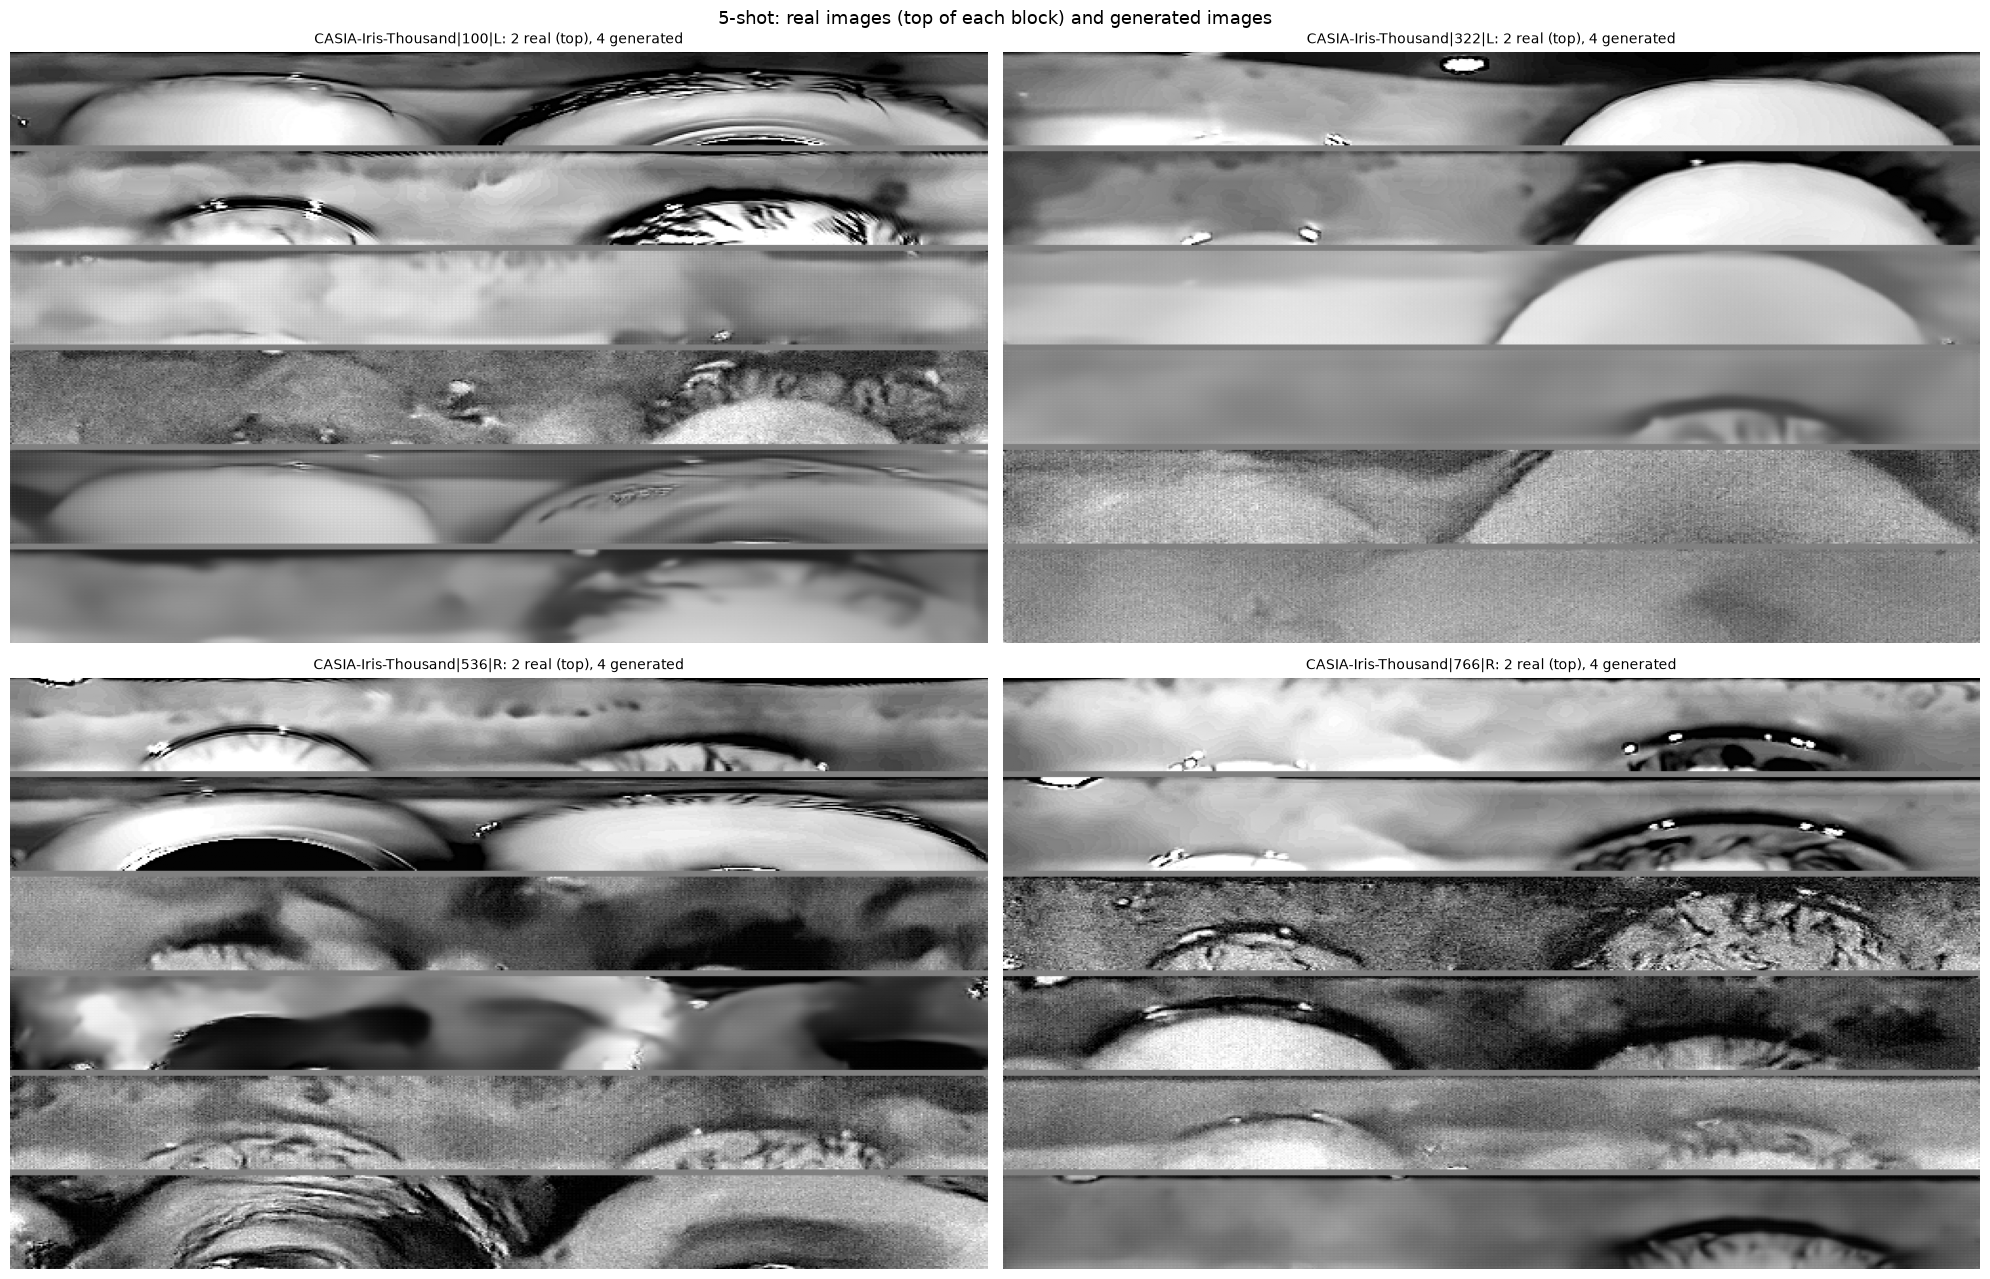

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_generation\real_vs_generated_5shot.png


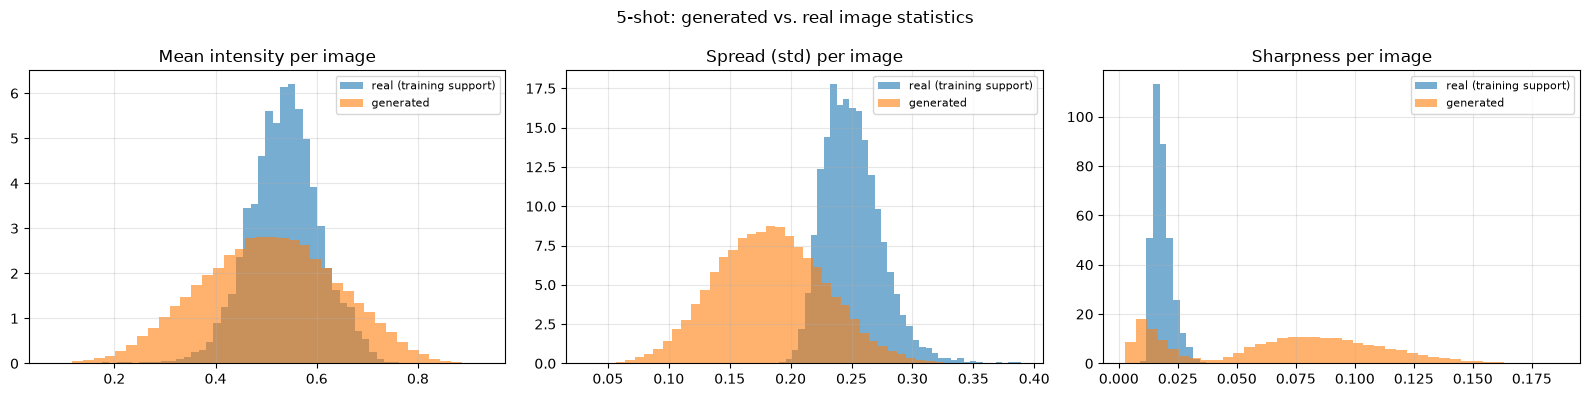

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_generation\generated_vs_real_statistics_5shot.png


In [15]:
# ============================================================
# 13. Real vs. generated figures
# ============================================================

def composite(strips, gap=4):
    parts = []
    for i, strip in enumerate(strips):
        parts.append(strip)
        if i < len(strips) - 1:
            parts.append(np.full((gap, strip.shape[1]), 0.5, dtype=strip.dtype))
    return np.vstack(parts)


def show_real_vs_generated(shot, n_real=2):
    group = synthetic_manifest[synthetic_manifest["shot"] == shot]
    classes = sorted(group["class_id"].unique())
    chosen_classes = classes[::max(1, len(classes) // FIGURE_IDENTITIES)][:FIGURE_IDENTITIES]

    support = long_manifest[(long_manifest["shot"] == shot) & (long_manifest["split"] == "train")
                            & (long_manifest["role"] == "support")]
    blocks, titles = [], []

    for class_id in chosen_classes:
        real = load_image_tensor(support[support["class_id"] == class_id].head(n_real)).numpy().astype(np.float32) / 255.0
        rows = group[group["class_id"] == class_id].sort_values("synth_index")
        pick = rows.iloc[np.unique(np.linspace(0, len(rows) - 1, FIGURE_GENERATED).round().astype(int))]
        generated = [cv2.imread(str(GENERATED_DIR / p), cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
                     for p in pick["relative_path"]]

        blocks.append(composite(list(real) + generated))
        titles.append(f"{class_id}: {len(real)} real (top), {len(generated)} generated")

    if not blocks:
        print("Nothing to show for", shot, "-shot")
        return

    rows_n = math.ceil(len(blocks) / 2)
    fig, axes = plt.subplots(rows_n, 2, figsize=(20, 6.5 * rows_n), squeeze=False)
    for ax in axes.flatten():
        ax.axis("off")
    for ax, block, title in zip(axes.flatten(), blocks, titles):
        ax.imshow(block, cmap="gray", vmin=0, vmax=1, aspect="auto")
        ax.set_title(title, fontsize=10)

    plt.suptitle(f"{shot}-shot: real images (top of each block) and generated images", fontsize=13)
    plt.tight_layout()
    path = RESULTS_DIR / f"real_vs_generated_{shot}shot.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved:", path)


largest_shot = int(synthetic_manifest["shot"].max())
show_real_vs_generated(largest_shot)

# ---- image statistics: generated vs. real ----
group = synthetic_manifest[synthetic_manifest["shot"] == largest_shot]
real = real_image_stats(largest_shot, group["class_id"].unique())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (key, title) in zip(axes, [("pixel_mean", "Mean intensity per image"),
                                   ("pixel_std", "Spread (std) per image"),
                                   ("sharpness", "Sharpness per image")]):
    ax.hist(real[key], bins=40, alpha=0.6, density=True, label="real (training support)")
    ax.hist(group[key], bins=40, alpha=0.6, density=True, label="generated")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle(f"{largest_shot}-shot: generated vs. real image statistics", fontsize=12)
plt.tight_layout()
stats_path = RESULTS_DIR / f"generated_vs_real_statistics_{largest_shot}shot.png"
plt.savefig(stats_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", stats_path)

## 14. Sanity checks

**Stop the notebook if:**
- a planned run is missing, or a manifest image is missing from disk;
- an identity does not have exactly the planned number of synthetic images, or image IDs / paths repeat;
- any synthetic identity is not a training identity, or any of its people appears in another split.

**Warn if** (these describe expected behaviour, not guaranteed behaviour):
- more than 1% of the images are near-constant (blank);
- generated images are duplicated;
- generated brightness differs from real brightness by more than 0.1, or sharpness differs by more than a factor of 2.

In [16]:
# ============================================================
# 14. Sanity checks
# ============================================================

checks = []


def add_check(name, passed, details="", critical=True):
    checks.append({"check": name, "passed": bool(passed), "critical": critical, "details": details})
    status = "PASS" if passed else ("FAIL" if critical else "WARN")
    print(f"[{status}] {name}" + (f"  ({details})" if details else ""))


expected_ids = {make_run_id(shot) for shot in plan}
missing_runs = expected_ids - set(runs_table["run_id"])
add_check("all planned runs are present", not missing_runs, f"{len(missing_runs)} missing")
add_check("every run passed the leakage guards", bool(runs_table["leakage_checks_passed"].all()))

absent = [p for p in synthetic_manifest["relative_path"] if not (GENERATED_DIR / p).exists()]
add_check("every image in the manifest exists on disk", not absent, f"{len(absent)} missing")

add_check("image IDs are unique", synthetic_manifest["image_id"].is_unique)
add_check("image paths are unique", synthetic_manifest["relative_path"].is_unique)

wrong_count = identity_summary[identity_summary["n_synthetic"] != TARGET_TOTAL_PER_IDENTITY - identity_summary["shot"]]
add_check("every identity has exactly the planned number of synthetic images", len(wrong_count) == 0,
          f"{len(wrong_count)} identities deviate")

complete = identity_summary[identity_summary["n_total"] != TARGET_TOTAL_PER_IDENTITY]
add_check(f"every identity ends with {TARGET_TOTAL_PER_IDENTITY} images (real + synthetic)", len(complete) == 0,
          f"{len(complete)} identities deviate")

# leakage: every synthetic identity must be a training identity, and no person may be shared with another split
leaks, shared_people = 0, 0
for shot, group in synthetic_manifest.groupby("shot"):
    rows = long_manifest[long_manifest["shot"] == shot]
    train_support = rows[(rows["split"] == "train") & (rows["role"] == "support") & (rows["dataset"].isin(TRAIN_DATASETS))]
    leaks += len(set(group["class_id"]) - set(train_support["class_id"]))
    held_out = set(rows.loc[~rows["class_id"].isin(set(train_support["class_id"])), "subject_key"])
    shared_people += len(set(group["subject_key"]) & held_out)

add_check("every synthetic identity is a training identity", leaks == 0, f"{leaks} are not")
add_check("no synthetic identity shares a person with the validation, test, or unseen data", shared_people == 0,
          f"{shared_people} people shared")
add_check("every synthetic image is labelled as a training image", bool((synthetic_manifest["split"] == "train").all()))

for _, row in quality_table.iterrows():
    shot = int(row["shot"])
    add_check(f"{shot}-shot: fewer than 1% near-constant images", row["near_constant_fraction"] < 0.01,
              f"{row['near_constant_fraction']:.3%}", critical=False)
    add_check(f"{shot}-shot: no duplicated generated images", row["duplicate_fraction"] == 0.0,
              f"{row['duplicate_fraction']:.3%} duplicates", critical=False)
    add_check(f"{shot}-shot: generated brightness is close to real brightness", abs(row["gen_mean"] - row["real_mean"]) <= 0.1,
              f"generated {row['gen_mean']:.3f} vs real {row['real_mean']:.3f}", critical=False)
    add_check(f"{shot}-shot: generated sharpness is within a factor of 2 of real sharpness", 0.5 <= row["sharpness_ratio"] <= 2.0,
              f"ratio {row['sharpness_ratio']:.2f}", critical=False)

sanity_report = pd.DataFrame(checks)
sanity_report.to_csv(RESULTS_DIR / "generation_sanity_checks.csv", index=False)
print("\nSaved:", RESULTS_DIR / "generation_sanity_checks.csv")

critical_failures = sanity_report[(~sanity_report["passed"]) & sanity_report["critical"]]
failed_names = list(critical_failures["check"])
assert len(critical_failures) == 0, f"Critical generation checks failed: {failed_names}"
print("\nGeneration sanity checks completed with no critical failures.")

[PASS] all planned runs are present  (0 missing)
[PASS] every run passed the leakage guards
[PASS] every image in the manifest exists on disk  (0 missing)
[PASS] image IDs are unique
[PASS] image paths are unique
[PASS] every identity has exactly the planned number of synthetic images  (0 identities deviate)
[PASS] every identity ends with 20 images (real + synthetic)  (0 identities deviate)
[PASS] every synthetic identity is a training identity  (0 are not)
[PASS] no synthetic identity shares a person with the validation, test, or unseen data  (0 people shared)
[PASS] every synthetic image is labelled as a training image
[PASS] 1-shot: fewer than 1% near-constant images  (0.000%)
[PASS] 1-shot: no duplicated generated images  (0.000% duplicates)
[PASS] 1-shot: generated brightness is close to real brightness  (generated 0.501 vs real 0.535)
[WARN] 1-shot: generated sharpness is within a factor of 2 of real sharpness  (ratio 3.33)
[PASS] 2-shot: fewer than 1% near-constant images  (0.0

## 15. Final outputs

At the end of Notebook 10, the project should contain:

```text
generated_images/
└── diffusion__<K>shot__seed<S>/
    ├── generation_signature.json         the settings that produced these images
    └── <dataset>/<identity>_<eye>/syn_000.png, syn_001.png, ...

results/synthetic_generation/
├── synthetic_manifest.csv                one row per synthetic image (the file later notebooks read)
├── identity_summary.csv                  real / synthetic / total images per identity
├── generation_runs.csv, generation_quality.csv, generation_sanity_checks.csv
├── manifests/<run_id>.csv                the manifest of one shot
├── runs/                                 one JSON record per shot
└── real_vs_generated_<K>shot.png, generated_vs_real_statistics_<K>shot.png
```

In [17]:
# ============================================================
# 15. Final output listing
# ============================================================

print("Generated images:", GENERATED_DIR)
for run_dir in sorted(p for p in GENERATED_DIR.iterdir() if p.is_dir()):
    print(f"- {run_dir.name}/  ({sum(1 for _ in run_dir.rglob('*.png'))} images)")

print("\nNotebook 10 results:", RESULTS_DIR)
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name}")

print(f"\nTotal synthetic images in the manifest: {len(synthetic_manifest)}")
print("\nNotebook 10 completed.")

Generated images: E:\Research\LargeScale_Synthetic_Iris_Generation\generated_images
- diffusion__1shot__seed42/  (26410 images)
- diffusion__2shot__seed42/  (24912 images)
- diffusion__3shot__seed42/  (23273 images)
- diffusion__5shot__seed42/  (19410 images)

Notebook 10 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\synthetic_generation
- generated_vs_real_statistics_5shot.png
- generation_quality.csv
- generation_runs.csv
- generation_sanity_checks.csv
- identity_summary.csv
- real_vs_generated_5shot.png
- synthetic_manifest.csv

Total synthetic images in the manifest: 94005

Notebook 10 completed.


## 16. What this notebook hands to Notebooks 11 to 13

```text
Notebook 09                Notebook 10                          Notebooks 11 - 13
Generator          --->    Synthetic images for every     --->  11: identity verification (accepted / rejected)
                           training identity                    12: diversity analysis
                           (generated_images/ + manifest)       13: train on real + accepted synthetic images
```

### The manifest

`results/synthetic_generation/synthetic_manifest.csv` has one row per synthetic image:

| Column | Meaning |
|---|---|
| `image_id`, `class_id`, `dataset`, `identity`, `eye`, `subject_key` | Which identity the image was generated for |
| `shot`, `split`, `source` | Shot count, always `train`, always `synthetic` |
| `synth_index`, `bank_index` | The image's index within its identity and the appearance-bank entry used |
| `relative_path` | Path **relative to `generated_images/`** |
| `generator_run_id`, `latent_run_id`, `sample_steps`, `guidance`, `eta`, `generation_seed` | Provenance and sampling settings |
| `pixel_mean`, `pixel_std`, `sharpness`, `content_hash` | Quick per-image statistics and a hash |

```python
manifest = pd.read_csv(RESULTS_DIR / "synthetic_manifest.csv", dtype={"identity": str, "eye": str})
path = GENERATED_DIR / manifest.loc[0, "relative_path"]
```

### How each later notebook uses it

| Notebook | Use |
|---|---|
| **11 Identity verification** | Embed each synthetic image and compare it with the real support images of its identity (cosine similarity); mark each image accepted or rejected. **Read the manifest, never glob the folder.** |
| **12 Diversity** | Measure how different the images of one identity are from each other and from the real ones. `bank_index` shows which appearance code produced each image. |
| **13 Final recognition** | Train on the real `train / support` images plus the **accepted** synthetic images only. Validation and test stay real. |
| **16 Ablations** | Images of one identity are ordered by `synth_index`, so "the first `m` synthetic images per identity" gives nested subsets (for example 5, 10, 20, 50). To get more images change `TARGET_TOTAL_PER_IDENTITY` and re-run: existing images are kept and only the new ones are generated. |

### Rules that keep the no-leakage guarantee intact

1. Synthetic images exist **only for training identities** and are used for training only. Never generate for, or add synthetic images to, validation, test, or the unseen dataset.
2. Evaluate on **real images only**, exactly as defined in Notebook 06.
3. Use the synthetic images of the **same shot** as the experiment.
4. Do not overwrite or edit the real few-shot dataset; the synthetic images live in their own folder.
5. Report the configuration fingerprint (`CONFIG_HASH`) and the generation seed with every number.
6. **The final comparison must include the traditional-augmentation baseline of Notebook 07**, because the generator was trained on appearance-transformed views of the real images (see Notebook 09, section 1.4).

### Reading the figures and checks

| What you see | Likely cause | What to try |
|---|---|---|
| Generated strips look like noise or blobs | The Notebook 09 generator is under-trained | Train it longer (Notebook 09: `TRAIN_STEPS`, `UNET_BASE`), then re-run this notebook |
| All images of one person look almost identical | Guidance too strong or appearance ignored | Lower `GUIDANCE_OVERRIDE`; check Notebook 09's appearance fidelity |
| Images do not look like the real person's iris | Identity is not followed | Raise `GUIDANCE_OVERRIDE`; check Notebook 09's identity consistency |
| Duplicated or near-constant images | Sampling problem | Check the figures; try more `SAMPLE_STEPS_OVERRIDE` |
| Brightness or sharpness differs from real | Under-training or over-guidance | Train the generator longer; lower guidance |